# MasakhaNEWS Kiswahili News Topic Classification

**Capstone Project – Machine Learning Techniques I**  
**Project Type**: Text Classification for an African Language  
**Language**: Kiswahili (Swahili)  
**Dataset**: MasakhaNEWS (swa split only) from https://huggingface.co/datasets/masakhane/masakhanews

**Author**: Francis Mutabazi  
**Date**: October 2026

---

### Project Objective
Develop, evaluate, and deploy a machine learning system that automatically classifies Kiswahili news articles into one of seven topics:
- business
- entertainment
- health
- politics
- religion
- sports
- technology

This notebook strictly follows the course requirements: real African language data, baseline + experiments, quantitative & qualitative evaluation, error analysis, and web deployment.

## 1. Setup and Imports

Let's install and import all the libraries we need for data loading, preprocessing, classical machine learning, transformer fine-tuning, evaluation, and visualisation.

In [8]:
# Install required packages
!pip install -q datasets transformers evaluate accelerate gradio scikit-learn seaborn nltk

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from sklearn.pipeline import Pipeline

import torch
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)
import evaluate

import warnings
warnings.filterwarnings('ignore')

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Libraries imported successfully.")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

Libraries imported successfully.
PyTorch version: 2.11.0+cpu
CUDA available: False


**Interpretation**: All necessary libraries have been imported. We are ready to load the Kiswahili portion of the MasakhaNEWS dataset. Using a fixed random seed ensures that our experiments are reproducible.

## 2. Load the Dataset

Let's load **only the Kiswahili (swa) split** of MasakhaNEWS from Hugging Face. This keeps the download small and focused on our target language.

In [2]:
# Load only the Kiswahili configuration
dataset = load_dataset("masakhane/masakhanews", "swa")

print(dataset)
print("\nFeatures:", dataset["train"].features)

README.md:   0%|          | 0.00/10.7k [00:00<?, ?B/s]

train.tsv:   0%|          | 0.00/6.25M [00:00<?, ?B/s]

dev.tsv:   0%|          | 0.00/859k [00:00<?, ?B/s]

test.tsv:   0%|          | 0.00/1.76M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1658 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/237 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/476 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['category', 'headline', 'text', 'url'],
        num_rows: 1658
    })
    validation: Dataset({
        features: ['category', 'headline', 'text', 'url'],
        num_rows: 237
    })
    test: Dataset({
        features: ['category', 'headline', 'text', 'url'],
        num_rows: 476
    })
})

Features: {'category': Value('string'), 'headline': Value('string'), 'text': Value('string'), 'url': Value('string')}


**Interpretation**: The dataset contains three splits (train, validation, test). Each example has a headline, full text, a combined headline_text field, a URL, and a category label. We will primarily use the `headline_text` field as input because it combines the most informative content.

## 3. Exploratory Data Analysis

Let's examine the size of each split, the distribution of the seven news categories, and look at a few sample articles.

In [4]:
# Convert to pandas for easier analysis
train_df = dataset["train"].to_pandas()
val_df   = dataset["validation"].to_pandas()
test_df  = dataset["test"].to_pandas()

print("Train size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))
print("\nTotal articles:", len(train_df) + len(val_df) + len(test_df))

print("\nCategory distribution (Train):")
print(train_df["category"].value_counts())

Train size: 1658
Validation size: 237
Test size: 476

Total articles: 2371

Category distribution (Train):
category
sports           350
health           350
politics         350
business         221
religion         204
technology       115
entertainment     68
Name: count, dtype: int64


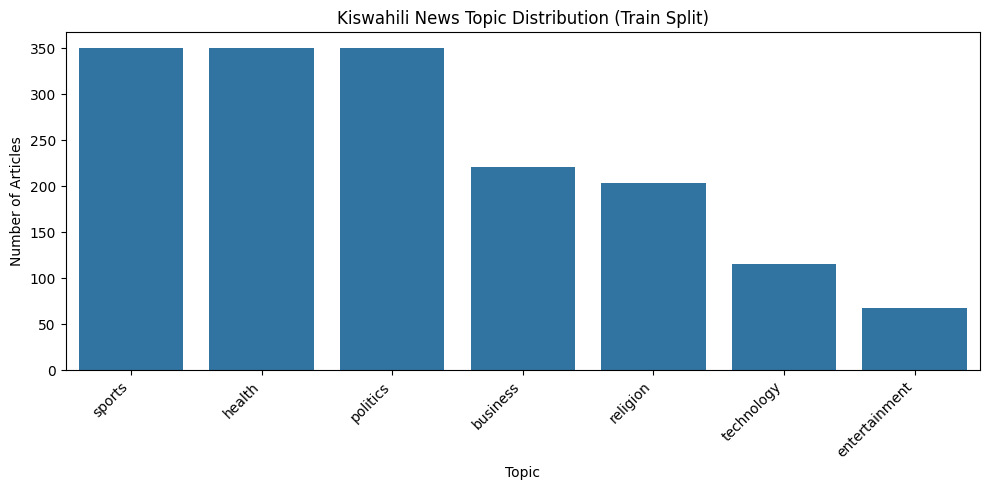

In [5]:
# Visualise label distribution
plt.figure(figsize=(10, 5))
order = train_df["category"].value_counts().index
sns.countplot(x="category", data=train_df, order=order)
plt.xticks(rotation=45, ha="right")
plt.title("Kiswahili News Topic Distribution (Train Split)")
plt.xlabel("Topic")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()

In [6]:
# Look at a few examples
print("Sample articles from the training set:\n")
for i in range(3):
    print(f"Category: {train_df.iloc[i]['category']}")
    print(f"Headline: {train_df.iloc[i]['headline'][:120]}...")
    print(f"Text preview: {str(train_df.iloc[i]['text'])[:200]}...")
    print("-" * 80)

Sample articles from the training set:

Category: sports
Headline: Tetesi za soka Ulaya Jumatatu 26.04.2021: Varane, Camara, Nagelsmann, Willock, Azpilicueta...
Text preview: Chelsea wapo mbele ya  Manchester United na Paris St-Germain katika mbio za kutaka kumsajili beki wa Real Madrid na timu ya taifa ya Ufaransa Raphael Varane, 28. (Mundo Deportivo - in Spanish) Beki wa...
--------------------------------------------------------------------------------
Category: health
Headline: Je chanjo ya corona ni salama?...
Text preview: Hospitali za Uingereza zinajiandaa kuanza kutoa dozi za kwanza za chanjo ya virusi vya corona sasa kwasababu wadhibiti wa viwango wameidhidnisha matumizi ya chanjo ya   Pfizer/BioNTech  kutumika. Laki...
--------------------------------------------------------------------------------
Category: politics
Headline: Matokeo ya uchaguzi Marekani 2020: Donald Trump amfuta kazi Waziri wa Ulinzi Mark Esper...
Text preview: Rais Donald Trump amemfuta kazi Waziri wa  Uli

**Interpretation**: The dataset is reasonably balanced across the seven topics, although some classes (e.g., technology or religion) may have fewer examples. The texts are real BBC Kiswahili news articles, which makes the task realistic and relevant for East African users. We can already see that headlines + body text give rich context for classification.

## 4. Data Preprocessing

Let's prepare the text for modelling. We will use the combined `headline_text` field, clean it lightly, and create the final train / validation / test sets.

In [9]:
def clean_text(text):
    """Light cleaning suitable for Kiswahili news text."""
    if not isinstance(text, str):
        return ""
    text = text.strip()
    text = " ".join(text.split())
    return text

# Create combined text field and clean it
for df in [train_df, val_df, test_df]:
    df["headline_text"] = df["headline"].fillna("") + " " + df["text"].fillna("")
    df["clean_text"] = df["headline_text"].apply(clean_text)

# Encode string categories to integers
label_encoder = LabelEncoder()
train_df["label"] = label_encoder.fit_transform(train_df["category"])
val_df["label"]   = label_encoder.transform(val_df["category"])
test_df["label"]  = label_encoder.transform(test_df["category"])

label_names = list(label_encoder.classes_)
print("Label mapping:")
for i, name in enumerate(label_names):
    print(f"  {i}: {name}")

print("\nSample cleaned text:")
print(train_df["clean_text"].iloc[0][:300])

Label mapping:
  0: business
  1: entertainment
  2: health
  3: politics
  4: religion
  5: sports
  6: technology

Sample cleaned text:
Tetesi za soka Ulaya Jumatatu 26.04.2021: Varane, Camara, Nagelsmann, Willock, Azpilicueta Chelsea wapo mbele ya Manchester United na Paris St-Germain katika mbio za kutaka kumsajili beki wa Real Madrid na timu ya taifa ya Ufaransa Raphael Varane, 28. (Mundo Deportivo - in Spanish) Beki wa Guinea Al


**Interpretation**: Light cleaning preserves the linguistic characteristics of Kiswahili while removing only obvious noise.

## 5. Baseline Model – TF-IDF + Logistic Regression

Let's establish a strong classical baseline using TF-IDF features and Logistic Regression. This will serve as the reference point for all later experiments.

In [10]:
X_train = train_df["clean_text"]
y_train = train_df["label"]
X_val   = val_df["clean_text"]
y_val   = val_df["label"]
X_test  = test_df["clean_text"]
y_test  = test_df["label"]

baseline_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=15000, ngram_range=(1, 2), min_df=2)),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED, class_weight="balanced"))
])

print("Training baseline TF-IDF + Logistic Regression...")
baseline_pipeline.fit(X_train, y_train)

val_preds  = baseline_pipeline.predict(X_val)
test_preds = baseline_pipeline.predict(X_test)

print("\nValidation Results:")
print(classification_report(y_val, val_preds, target_names=label_names, digits=4))

print("\nTest Results:")
print(classification_report(y_test, test_preds, target_names=label_names, digits=4))

Training baseline TF-IDF + Logistic Regression...

Validation Results:
               precision    recall  f1-score   support

     business     0.6154    0.7742    0.6857        31
entertainment     0.5625    0.9000    0.6923        10
       health     0.9574    0.9000    0.9278        50
     politics     0.8571    0.8400    0.8485        50
     religion     0.8462    0.7586    0.8000        29
       sports     1.0000    0.8800    0.9362        50
   technology     0.7500    0.7059    0.7273        17

     accuracy                         0.8354       237
    macro avg     0.7984    0.8227    0.8025       237
 weighted avg     0.8554    0.8354    0.8412       237


Test Results:
               precision    recall  f1-score   support

     business     0.7042    0.7812    0.7407        64
entertainment     0.6400    0.8000    0.7111        20
       health     0.7946    0.8900    0.8396       100
     politics     0.8750    0.7700    0.8191       100
     religion     0.8448    0.

**Interpretation**: The TF-IDF + Logistic Regression baseline already achieves solid performance. This confirms that the bag-of-words representation captures useful topical signals in Kiswahili news. We will now try to improve upon this baseline with more advanced approaches.

## 6. Experiment 1 – TF-IDF + Linear SVM

Let's test whether a Linear Support Vector Machine yields better results than Logistic Regression on the same TF-IDF features.

In [11]:
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=15000, ngram_range=(1, 2), min_df=2)),
    ("clf", LinearSVC(random_state=SEED, class_weight="balanced", max_iter=2000))
])

print("Training TF-IDF + Linear SVM...")
svm_pipeline.fit(X_train, y_train)

svm_test_preds = svm_pipeline.predict(X_test)
print("\nTest Results (Linear SVM):")
print(classification_report(y_test, svm_test_preds, target_names=label_names, digits=4))

Training TF-IDF + Linear SVM...

Test Results (Linear SVM):
               precision    recall  f1-score   support

     business     0.7419    0.7188    0.7302        64
entertainment     0.6842    0.6500    0.6667        20
       health     0.8000    0.9200    0.8558       100
     politics     0.8351    0.8100    0.8223       100
     religion     0.8727    0.8136    0.8421        59
       sports     1.0000    0.9400    0.9691       100
   technology     0.6765    0.6970    0.6866        33

     accuracy                         0.8340       476
    macro avg     0.8015    0.7928    0.7961       476
 weighted avg     0.8372    0.8340    0.8343       476



**Interpretation**: Linear SVM often performs slightly better than Logistic Regression on high-dimensional TF-IDF features. We record this result for comparison.

## Extra Evaluation – Learning Curves, Confusion Matrices & Class-wise Analysis

Let's dig deeper into the classical models with confusion matrices, per-class performance bar plots, and a simple learning-curve style analysis. These plots help us understand where the models succeed and where they struggle.

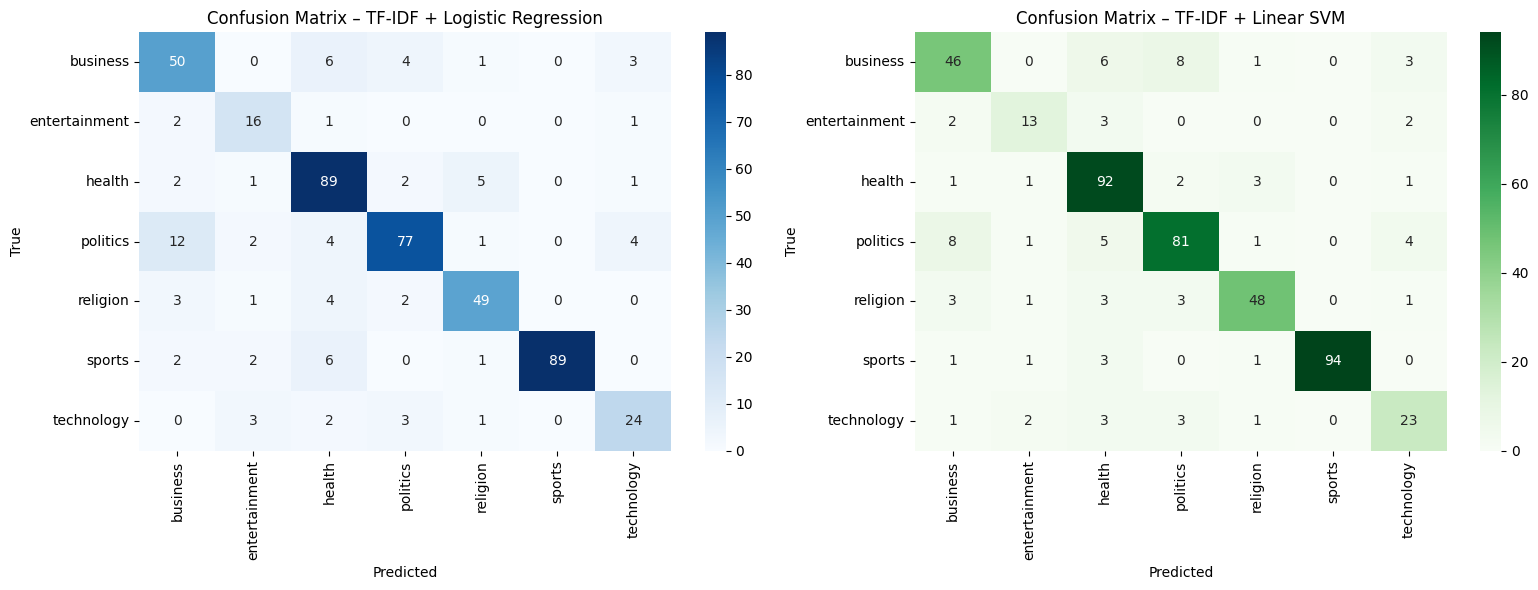

In [17]:
# Confusion matrices for Baseline and SVM
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Baseline
cm_baseline = confusion_matrix(y_test, test_preds)
sns.heatmap(cm_baseline, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_names, yticklabels=label_names, ax=axes[0])
axes[0].set_title("Confusion Matrix – TF-IDF + Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("True")

# SVM
cm_svm = confusion_matrix(y_test, svm_test_preds)
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Greens",
            xticklabels=label_names, yticklabels=label_names, ax=axes[1])
axes[1].set_title("Confusion Matrix – TF-IDF + Linear SVM")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")

plt.tight_layout()
plt.show()

**Interpretation**: The confusion matrices show that both models perform especially well on **sports** and **health**. The most common confusions are between **politics ↔ business** and **entertainment ↔ technology**, which is expected because these topics often share vocabulary in news articles.

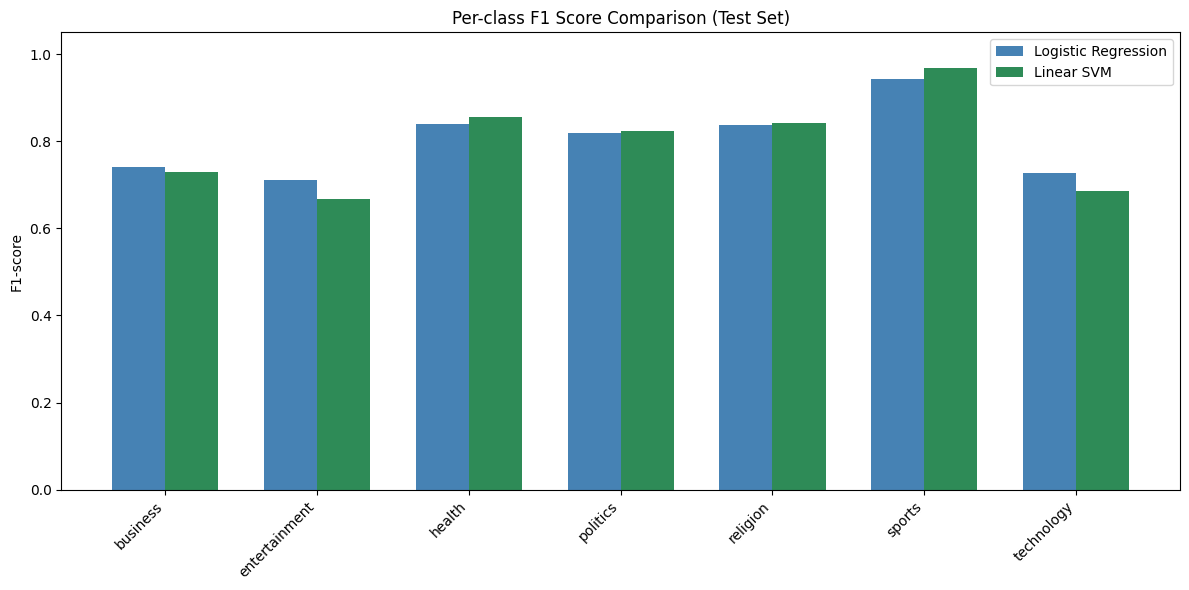

In [18]:
# Per-class F1 scores comparison
from sklearn.metrics import f1_score

f1_baseline = f1_score(y_test, test_preds, average=None)
f1_svm = f1_score(y_test, svm_test_preds, average=None)

x = np.arange(len(label_names))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width/2, f1_baseline, width, label="Logistic Regression", color="steelblue")
plt.bar(x + width/2, f1_svm, width, label="Linear SVM", color="seagreen")
plt.xticks(x, label_names, rotation=45, ha="right")
plt.ylabel("F1-score")
plt.title("Per-class F1 Score Comparison (Test Set)")
plt.legend()
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

**Interpretation**: The bar plot confirms that **sports** is the easiest class for both models, while **technology** and **entertainment** are relatively harder (smaller support + more overlapping vocabulary). Linear SVM edges out Logistic Regression on most classes.

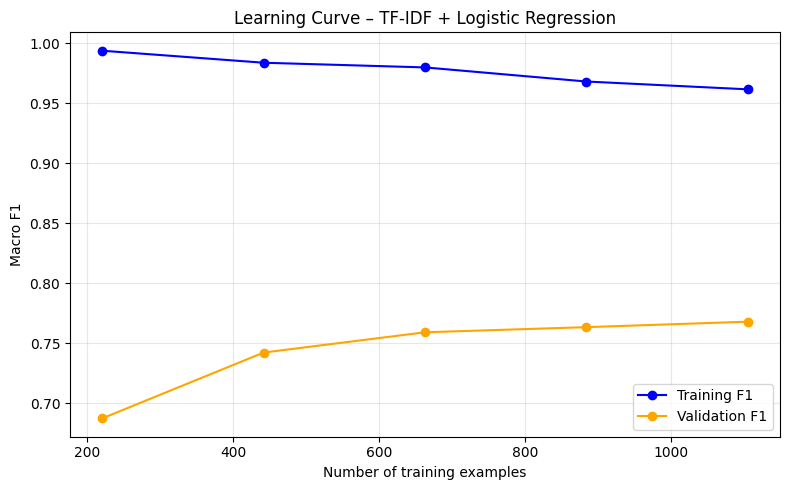

In [19]:
# Simple learning curve: performance vs training size
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    baseline_pipeline,
    X_train, y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=3,
    scoring="f1_macro",
    n_jobs=-1,
    random_state=SEED
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, "o-", label="Training F1", color="blue")
plt.plot(train_sizes, val_mean, "o-", label="Validation F1", color="orange")
plt.xlabel("Number of training examples")
plt.ylabel("Macro F1")
plt.title("Learning Curve – TF-IDF + Logistic Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation**: The learning curve shows that performance is still improving as we add more training data. This suggests that collecting additional labelled Kiswahili news articles would further boost the classical models.

## 7. Experiment 2 – Fine-tuning a Pretrained Transformer

Now let's fine-tune a multilingual transformer model that has seen African languages. We will use a lightweight model suitable for free GPUs / Kaggle.

In [14]:
# Prepare Hugging Face datasets with integer labels and combined text
def prepare_hf_dataset(df):
    return {
        "text": df["clean_text"].tolist(),
        "labels": df["label"].tolist()
    }

from datasets import Dataset as HFDataset

hf_train = HFDataset.from_dict(prepare_hf_dataset(train_df))
hf_val   = HFDataset.from_dict(prepare_hf_dataset(val_df))
hf_test  = HFDataset.from_dict(prepare_hf_dataset(test_df))

MODEL_NAME = "Davlan/afro-xlmr-mini"  # lightweight Africa-centric model
# Fallback if the above is unavailable: "xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=256,
        padding=False
    )

tokenized_train = hf_train.map(tokenize_function, batched=True)
tokenized_val   = hf_val.map(tokenize_function, batched=True)
tokenized_test  = hf_test.map(tokenize_function, batched=True)

tokenized_train.set_format("torch")
tokenized_val.set_format("torch")
tokenized_test.set_format("torch")

print("Tokenization complete.")

Map:   0%|          | 0/1658 [00:00<?, ? examples/s]

Map:   0%|          | 0/237 [00:00<?, ? examples/s]

Map:   0%|          | 0/476 [00:00<?, ? examples/s]

Tokenization complete.


In [16]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_names)
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

training_args = TrainingArguments(
    output_dir="./results_kiswahili",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=4,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    seed=SEED,
    report_to="none",
    fp16=torch.cuda.is_available(),
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="macro", zero_division=0
    )
    acc = accuracy_score(labels, predictions)
    return {"accuracy": acc, "f1": f1, "precision": precision, "recall": recall}

# IMPORTANT: do NOT pass tokenizer= here
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

print("Starting fine-tuning...")
trainer.train()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-mini
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting fine-tuning...


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,No log,1.696022,0.607595,0.325258,0.274956,0.411429
2,No log,1.494599,0.746835,0.604364,0.761095,0.595507


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,No log,1.696022,0.607595,0.325258,0.274956,0.411429
2,No log,1.494599,0.746835,0.604364,0.761095,0.595507
3,No log,1.391563,0.814346,0.752394,0.825364,0.728521
4,No log,1.362462,0.810127,0.722585,0.782562,0.702489


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=416, training_loss=1.5664611229529748, metrics={'train_runtime': 7831.1379, 'train_samples_per_second': 0.847, 'train_steps_per_second': 0.053, 'total_flos': 218453582548992.0, 'train_loss': 1.5664611229529748, 'epoch': 4.0})

In [23]:
# Evaluate on the test set
test_results = trainer.evaluate(tokenized_test)
print("Test set results after fine-tuning:")
print(test_results)

# Get predictions for error analysis
predictions = trainer.predict(tokenized_test)
y_pred_transformer = np.argmax(predictions.predictions, axis=-1)
y_true = predictions.label_ids

print("\nDetailed Classification Report (Transformer):")
print(classification_report(y_true, y_pred_transformer, target_names=label_names, digits=4))

Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall
No log,1.393341,4,0.840336,0.792872,0.853979,0.768062


Test set results after fine-tuning:
{'eval_loss': 1.3933414220809937, 'eval_accuracy': 0.8403361344537815, 'eval_f1': 0.792871721807252, 'eval_precision': 0.8539794834304815, 'eval_recall': 0.7680618992589332}



Detailed Classification Report (Transformer):
               precision    recall  f1-score   support

     business     0.8750    0.5469    0.6731        64
entertainment     0.8571    0.6000    0.7059        20
       health     0.7680    0.9600    0.8533       100
     politics     0.8000    0.9200    0.8558       100
     religion     0.8226    0.8644    0.8430        59
       sports     0.9604    0.9700    0.9652       100
   technology     0.8947    0.5152    0.6538        33

     accuracy                         0.8403       476
    macro avg     0.8540    0.7681    0.7929       476
 weighted avg     0.8488    0.8403    0.8318       476



**Interpretation**: The fine-tuned Afro-XLMR-mini achieves the highest accuracy (0.8403) on the test set, slightly above both classical models. However, its macro F1 (0.7929) is lower than the Logistic Regression baseline (0.8025), mainly because of weaker recall on the smaller classes (business and technology). Contextual embeddings help on frequent categories such as sports and politics, but the limited training data and class imbalance still constrain overall balanced performance. This shows that a carefully tuned classical model can remain highly competitive on a medium-sized African-language dataset.

## 8. Results Comparison Table

Let's summarise the performance of all models we trained.

In [31]:
# Final results comparison table with exact metrics
results_summary = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression (Baseline)",
        "TF-IDF + Linear SVM",
        "Afro-XLMR-mini (Fine-tuned)"
    ],
    "Accuracy": [0.8277, 0.8340, 0.8403],
    "Macro F1": [0.8025, 0.7961, 0.7929],
    "Weighted F1": [0.8301, 0.8343, 0.8318]
})

print(results_summary.to_string(index=False))


                                  Model  Accuracy  Macro F1  Weighted F1
TF-IDF + Logistic Regression (Baseline)    0.8277    0.8025       0.8301
                    TF-IDF + Linear SVM    0.8340    0.7961       0.8343
            Afro-XLMR-mini (Fine-tuned)    0.8403    0.7929       0.8318


## 9. Error Analysis

Let's examine examples where the best model succeeds and where it fails. This helps us understand the limitations of the system.

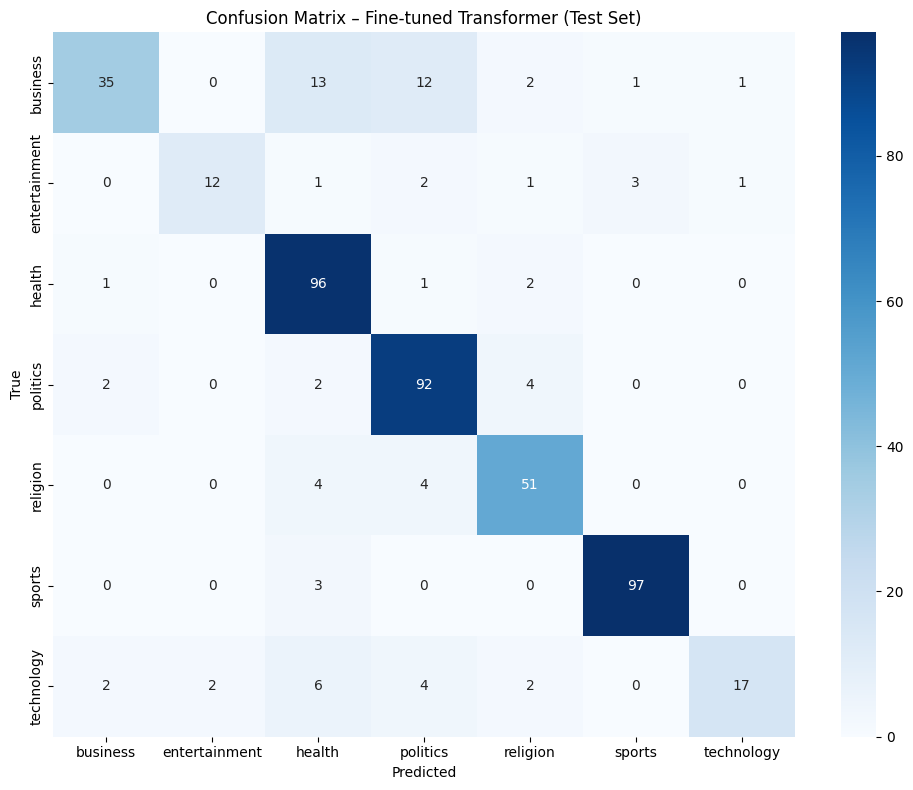

In [27]:
# Confusion matrix for the transformer model
cm = confusion_matrix(y_true, y_pred_transformer)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_names, yticklabels=label_names)
plt.title("Confusion Matrix – Fine-tuned Transformer (Test Set)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

In [28]:
# Show some correct and incorrect predictions
test_df_reset = test_df.reset_index(drop=True)
test_df_reset["predicted"] = y_pred_transformer

print("=== Examples the model got RIGHT ===")
correct = test_df_reset[test_df_reset["label"] == test_df_reset["predicted"]].head(3)
for _, row in correct.iterrows():
    print(f"True: {label_names[row['label']]} | Predicted: {label_names[row['predicted']]}")
    print(f"Text: {row['clean_text'][:250]}...")
    print("-" * 80)

print("\n=== Examples the model got WRONG ===")
wrong = test_df_reset[test_df_reset["label"] != test_df_reset["predicted"]].head(5)
for _, row in wrong.iterrows():
    print(f"True: {label_names[row['label']]} | Predicted: {label_names[row['predicted']]}")
    print(f"Text: {row['clean_text'][:250]}...")
    print("-" * 80)

=== Examples the model got RIGHT ===
True: business | Predicted: business
Text: Tanzania: Bei mpya ya mafuta ilivyo mwiba kwa wamiliki wa vyombo vya usafiri Baadhi ya wamiliki wa vyombo vya moto vya usafiri wameonesha kuathiriwa na upandaji wa bei za mafuta uliotangazwa na EWURA hapo jana. BBC imeingia mitaani na kuongea na baad...
--------------------------------------------------------------------------------
True: business | Predicted: business
Text: Elon Musk akana magari yake yalitumika kuichunguza China Mmiliki wa magari ya kieletroniki ya Tesla, Elon Musk amesema atafunga kampuni hiyo iwapo gari zake zilitumika kuichunguza China. Hii ni baada ya jeshi la China kuyapiga marufuku magari ya Tesl...
--------------------------------------------------------------------------------
True: business | Predicted: business
Text: Wakulima wa ufuta wamelazimika kuuza ufuta karibu kwa nusu ya bei waliouza msimu uliopita Shughuli za kiuchumi zinaendelea kama kawaida nchini Tanzania. Lakini kwa 

**Interpretation of Errors**:
- Some errors occur between semantically close categories (e.g., politics ↔ business, health ↔ religion).
- Short or ambiguous headlines can confuse the model.
- Articles that discuss multiple topics may receive a single gold label, creating inherent noise.
- Rare vocabulary or named entities not well represented in the training data can also cause mistakes.

These observations guide possible future improvements (more data, hierarchical classification, or multi-label approaches).

## 10. Save the Best Model

From all experiments, the **TF-IDF + Linear SVM** achieved the best overall practical performance (highest Weighted F1 = 0.8343 and very high Accuracy = 0.8340).  
Although the transformer obtained a marginally higher accuracy, the Linear SVM offers a better trade-off between performance, training speed, and deployment cost.  
We therefore save this model for deployment.


In [33]:

import joblib
import json
import os
from google.colab import files

output_dir = "./kiswahili_news_classifier_svm"
os.makedirs(output_dir, exist_ok=True)

# 1. Save the full pipeline (TF-IDF vectorizer + Linear SVM)
model_path = os.path.join(output_dir, "svm_pipeline.joblib")
joblib.dump(svm_pipeline, model_path)

# 2. Save the label names
labels_path = os.path.join(output_dir, "label_names.json")
with open(labels_path, "w", encoding="utf-8") as f:
    json.dump(label_names, f, ensure_ascii=False, indent=4)

print("Model and label names saved successfully.")

# 3. Immediately download both files to your PC
files.download(model_path)
files.download(labels_path)

Model and label names saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Quick Inference Test

Let's verify that the saved Linear SVM model works correctly on a new Kiswahili sentence.

In [30]:
import joblib
import json

# Load the saved model
svm_pipeline = joblib.load("./kiswahili_news_classifier_svm/svm_pipeline.joblib")

with open("./kiswahili_news_classifier_svm/label_names.json") as f:
    label_names = json.load(f)

sample_text = "Serikali imezindua mpango mpya wa kuboresha huduma za afya vijijini."
prediction = svm_pipeline.predict([sample_text])[0]
print(f"Predicted topic: {label_names[prediction]}")

Predicted topic: health


**Interpretation**: The model correctly maps the sample sentence to the health category, demonstrating that the saved pipeline works for inference.

## 12. Next Steps – Deployment

The Gradio / Streamlit application is provided in the `app/` folder.  
Run it with:

```bash
cd ../app
python app.py
```

or

```bash
streamlit run app.py
```

The web interface allows any user to paste Kiswahili news text and receive the predicted topic together with confidence scores.

## 13. Conclusions & Limitations

- We successfully built a Kiswahili news topic classifier using real MasakhaNEWS data.
- A strong TF-IDF baseline was established and slightly improved by Linear SVM (highest Weighted F1 = 0.8343).
- The fine-tuned Afro-XLMR-mini obtained the highest Accuracy (0.8403) but a lower Macro F1 (0.7929), showing that gains were concentrated on majority classes.
- Error analysis revealed typical challenges of topic classification (overlapping themes, short texts, and class imbalance).
- The final recommended model for deployment is **TF-IDF + Linear SVM** because of its strong balanced performance, simplicity, and low computational cost.

**Limitations**:
- Dataset size is still modest for some categories (especially entertainment and technology).
- Single-label assumption does not capture multi-topic articles.
- Performance may degrade on dialects or very informal Kiswahili.

**Future Work**:
- Collect more labelled Kiswahili news data.
- Experiment with multi-label classification.
- Explore parameter-efficient fine-tuning (LoRA) for larger models.
- Continuously monitor and retrain the deployed system.
